#00. Import Library

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#01. Image preparation

beatles_zoom.png : (173, 615)  range 0 ~ 254
stroke ~4 px  -> wider than the 3x3 structuring elements
bright pixels (> 128) 20754 (19.5%) | mean 56.48


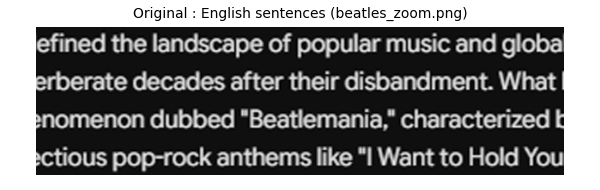

In [ ]:
TEXT_PATH = 'beatles_zoom.png'
text = cv2.imread(TEXT_PATH, cv2.IMREAD_GRAYSCALE)
assert text is not None, f'이미지를 찾을 수 없음 : {TEXT_PATH} 를 업로드한 뒤 다시 실행하세요'


def stroke_width(im):
    """Peel the strokes with 3x3 erosions until they are gone; each pass removes 1 px per side."""
    sq, cur = np.ones((3, 3), np.uint8), (im > 128).astype(np.uint8)
    n, k = cur.sum(), 0
    while cur.sum() > 0.05 * n and k < 20:
        cur = cv2.erode(cur, sq); k += 1
    return 2 * k


n0 = np.count_nonzero(text > 128)   # bright pixels = letter strokes
m0 = text.mean()
sw = stroke_width(text)

# strokes must be WIDER than the structuring element, otherwise erosion deletes instead of shrinking
print(f'{TEXT_PATH} : {text.shape}  range {text.min()} ~ {text.max()}')
print(f'stroke ~{sw} px  -> {"wider" if sw > 3 else "THINNER"} than the 3x3 structuring elements')
print(f'bright pixels (> 128) {n0} ({100 * n0 / text.size:.1f}%) | mean {m0:.2f}')


def show(images, titles, cols=1):
    """The image is a wide strip, so results are stacked vertically rather than side by side."""
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(6 * cols, 1.9 * rows))
    for i, (im, t) in enumerate(zip(images, titles), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(t, fontsize=10); plt.axis('off')
    plt.tight_layout(); plt.show()


show([text], ['Original : English sentences (beatles_zoom.png)'])

#02_1. Structuring Element

In [ ]:
# Rules : 4 structuring element, padding for printing same_size
SES = [
    ('Vertical 3x1',    np.ones((3, 1), np.uint8),                          'Top 1, Bottom 1'),
    ('Horizontal 1x3',  np.ones((1, 3), np.uint8),                          'Left 1, Right 1'),
    ('Square 3x3',      np.ones((3, 3), np.uint8),                          'All four sides, 1'),
    ('Circle/disk 3x3', cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3)), 'All four sides, 1'),
]

for name, se, pad in SES:
    print(f'[{name}]  padding : {pad}\n{se}\n')

[Vertical 3x1]  padding : Top 1, Bottom 1
[[1]
 [1]
 [1]]

[Horizontal 1x3]  padding : Left 1, Right 1
[[1 1 1]]

[Square 3x3]  padding : All four sides, 1
[[1 1 1]
 [1 1 1]
 [1 1 1]]

[Circle/disk 3x3]  padding : All four sides, 1
[[0 1 0]
 [1 1 1]
 [0 1 0]]



#02_2. Common demo helper

In [ ]:
def morph_demo(op, name, ref=None):   # ref = (op, name) : drawn in the left column for comparison
    ops = [ref, (op, name)] if ref else [(op, name)]

    # (1) original + the four structuring elements
    images = [text] * len(ops)
    titles = ['Original'] * len(ops)
    for n, se, p in SES:
        images += [f(text, se) for f, _ in ops]
        titles += [f'{m} - {n}  (padding : {p})' for _, m in ops]
    show(images, titles, cols=len(ops))

    # (2) numbers
    print(f'\noriginal : bright pixels (> 128) {n0} | mean {m0:.2f}')
    print(f'{"Structuring element":<20}' + ''.join(f'{m + " pixels":<20}{m + " mean":<18}' for _, m in ops))
    print('-' * (20 + 38 * len(ops)))
    for n, se, _ in SES:
        row = f'{n:<20}'
        for f, _ in ops:
            r = f(text, se)
            c = np.count_nonzero(r > 128)
            row += f'{f"{c} ({100 * c / n0 - 100:+.1f}%)":<20}{f"{r.mean():.2f} ({r.mean() - m0:+.2f})":<18}'
        print(row)

#02_3. Dilation - structuring elements & padding

A 7x7 toy array with three isolated dots makes the mechanism explicit before it is applied to the
text: each `1` is replaced by a copy of the structuring element, so a single dot becomes a vertical
bar, a horizontal bar, a 3x3 block or a cross.

In [ ]:
# 7x7 example
toy = np.zeros((7, 7), np.uint8)
toy[3, 3], toy[1, 5], toy[5, 1] = 1, 1, 1
print('input (7x7)\n', toy, '\n')

for name, se, pad in SES:
    out = cv2.dilate(toy, se)
    print(f'[{name}]  padding : {pad}  {toy.shape} -> {out.shape}\n{out}\n')

input (7x7)
 [[0 0 0 0 0 0 0]
 [0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0]] 

[Vertical 3x1]  padding : Top 1, Bottom 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 1 0]
 [0 0 0 0 0 1 0]
 [0 0 0 1 0 1 0]
 [0 0 0 1 0 0 0]
 [0 1 0 1 0 0 0]
 [0 1 0 0 0 0 0]
 [0 1 0 0 0 0 0]]

[Horizontal 1x3]  padding : Left 1, Right 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 1 1 1]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Square 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 1 1 1]
 [0 0 0 0 1 1 1]
 [0 0 1 1 1 1 1]
 [0 0 1 1 1 0 0]
 [1 1 1 1 1 0 0]
 [1 1 1 0 0 0 0]
 [1 1 1 0 0 0 0]]

[Circle/disk 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 1 0]
 [0 0 0 0 1 1 1]
 [0 0 0 1 0 1 0]
 [0 0 1 1 1 0 0]
 [0 1 0 1 0 0 0]
 [1 1 1 0 0 0 0]
 [0 1 0 0 0 0 0]]



#02_4. Dilation on the text image

**Result** The letters get visibly bolder and the counters (the holes in `e`, `a`, `o`)
start to close. The growth is strictly directional: `Vertical 3x1` stretches the strokes up and
down, so the lines of text begin to reach for each other vertically, while `Horizontal 1x3` widens
them sideways and makes neighbouring letters touch, closing the word spacing first. Because the two
1-D elements only reach along one axis they add a similar, moderate amount of ink (+32.1% and
+37.4% bright pixels), whereas `Square 3x3` grows along both axes at once and changes the most
(+70.0%), with `Circle/disk 3x3` (4-neighbours only) landing in between (+53.4%).

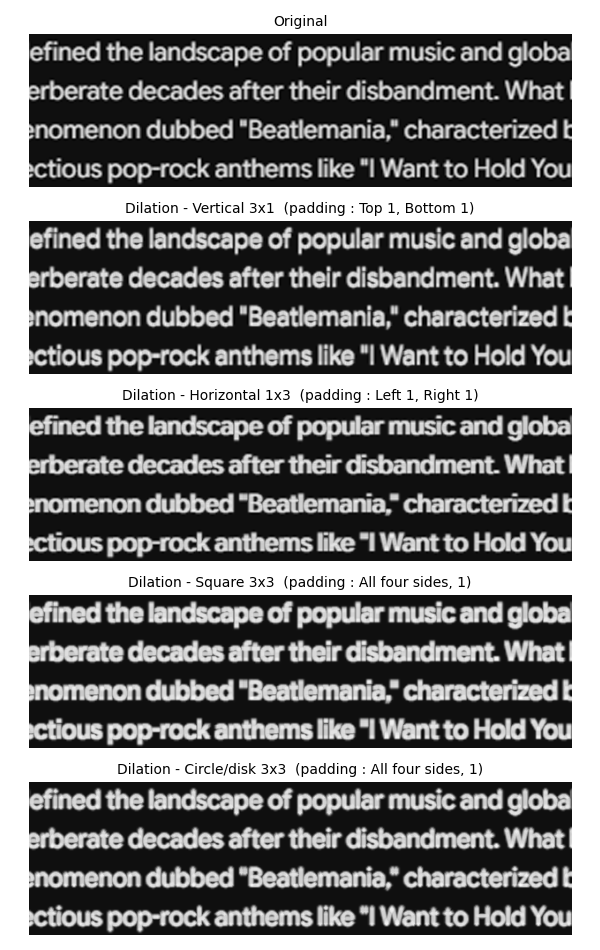


original : bright pixels (> 128) 20754 | mean 56.48
Structuring element Dilation pixels     Dilation mean     
----------------------------------------------------------
Vertical 3x1        27414 (+32.1%)      69.40 (+12.93)    
Horizontal 1x3      28512 (+37.4%)      70.71 (+14.23)    
Square 3x3          35290 (+70.0%)      83.66 (+27.18)    
Circle/disk 3x3     31834 (+53.4%)      77.43 (+20.95)    


In [ ]:
# strokes grow along the shape of the structuring element, so the letters get thicker
morph_demo(cv2.dilate, 'Dilation')

#03_1. Erosion - structuring elements & padding

The dual of 02_3. The toy array is a filled 5x5 block plus one isolated dot, because erosion
*shrinks*: the block loses its border and the isolated dot - being smaller than the structuring
element - disappears entirely. That single dot is the whole idea behind noise removal in 05_1.

In [ ]:
# 7x7 example : erosion shrinks a region, so start from a filled block + an isolated dot
toy_e = np.zeros((7, 7), np.uint8)
toy_e[1:6, 1:6], toy_e[0, 0] = 1, 1
print('input (7x7)\n', toy_e, '\n')

for name, se, pad in SES:
    out = cv2.erode(toy_e, se)
    print(f'[{name}]  padding : {pad}  {toy_e.shape} -> {out.shape}\n{out}\n')

input (7x7)
 [[1 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]] 

[Vertical 3x1]  padding : Top 1, Bottom 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Horizontal 1x3]  padding : Left 1, Right 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]]

[Square 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

[Circle/disk 3x3]  padding : All four sides, 1  (7, 7) -> (7, 7)
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]



#03_2. Erosion on the text image

**Result** The text turns thin and faint, and the drop is far from uniform across the
four elements: the 1-D elements survive much better (-32.0% and -38.0%) than the square (-68.9%),
because a vertical element only attacks a stroke from above and below and therefore leaves vertical
stems - the stems of `d`, `b`, `l` - standing, while a horizontal element leaves the horizontal
bars. `Square 3x3` attacks from all eight neighbours at once and removes the most. This asymmetry is
what makes erosion usable as a *direction-selective* filter, and it is invisible if only a square
element is tested.

Note that erosion is **not** invertible: once a stroke is thinner than the element it is gone, and
no later dilation can bring it back. That is exactly what the opening in 04_1 has to live with, and
it is why the opening column never returns to 100%.

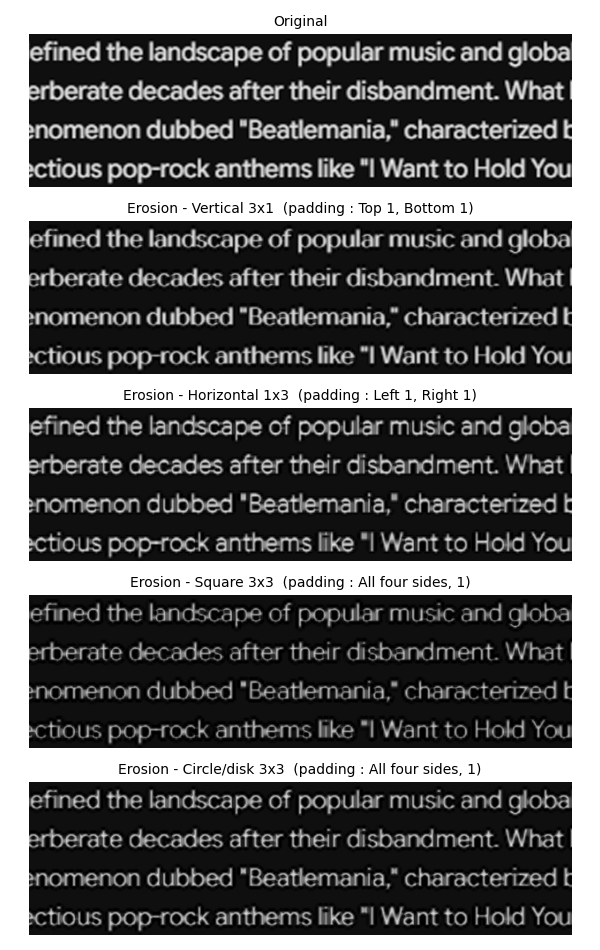


original : bright pixels (> 128) 20754 | mean 56.48
Structuring element Erosion pixels      Erosion mean      
----------------------------------------------------------
Vertical 3x1        14111 (-32.0%)      43.67 (-12.80)    
Horizontal 1x3      12863 (-38.0%)      42.31 (-14.17)    
Square 3x3          6454 (-68.9%)       30.28 (-26.19)    
Circle/disk 3x3     9813 (-52.7%)       35.79 (-20.69)    


In [ ]:
# strokes thinner than the structuring element disappear completely,
# 1-D elements keep only the strokes that are parallel to them
morph_demo(cv2.erode, 'Erosion')

#04_1. Opening on the text image

**Result** The left column is plain erosion and the right column is opening, which makes
the point of the operation obvious: erosion thins the text to the edge of legibility (-68.9% for the
square element), and the following dilation puts the thickness back, so the opened text is close to
the original (-8.4%) while erosion is not. What does *not* come back is anything the erosion step
deleted completely - detail finer than the structuring element.

Opening is therefore a filter that
**removes structures smaller than the element and leaves larger ones essentially unchanged**

This is the property that section 05_1 puts to work on real noise.

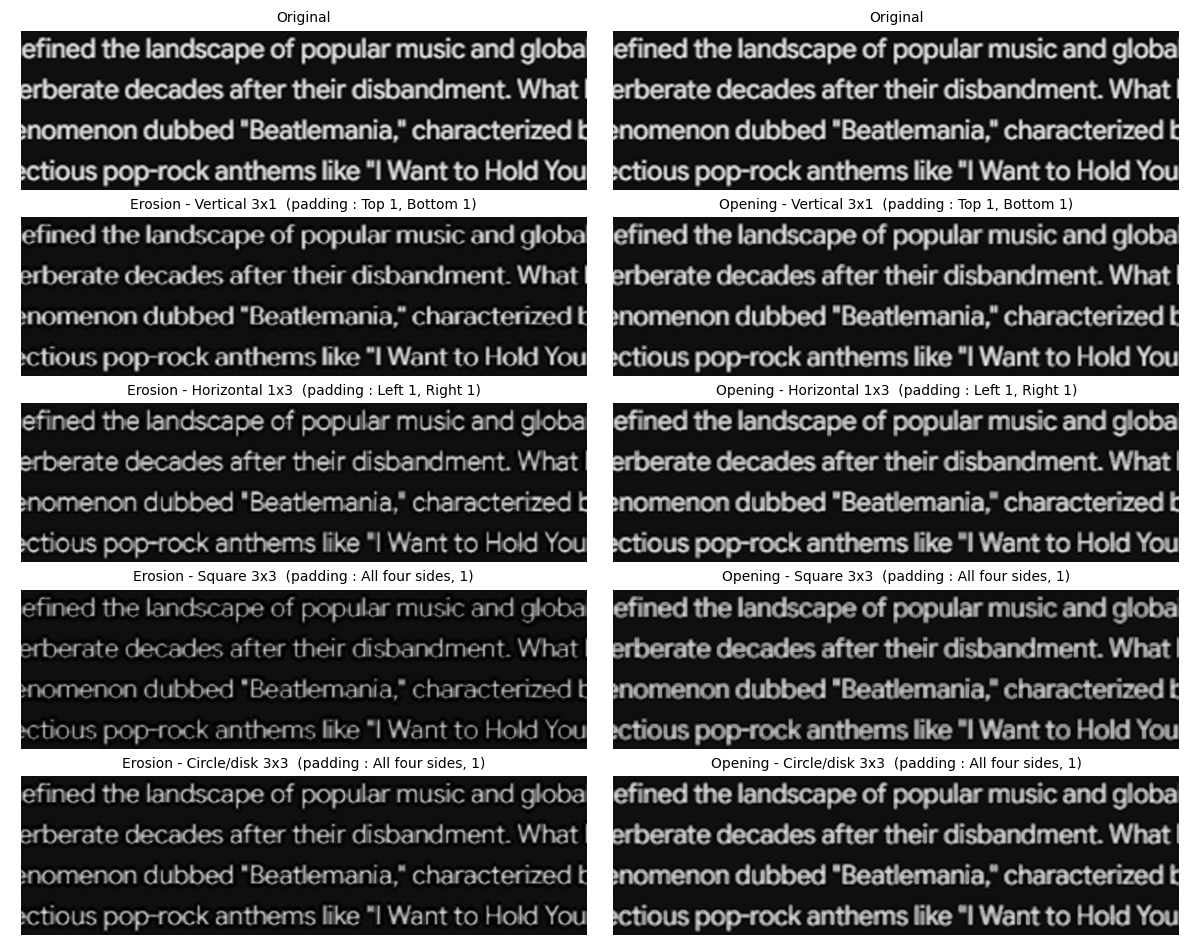


original : bright pixels (> 128) 20754 | mean 56.48
Structuring element Erosion pixels      Erosion mean      Opening pixels      Opening mean      
------------------------------------------------------------------------------------------------
Vertical 3x1        14111 (-32.0%)      43.67 (-12.80)    20225 (-2.5%)       54.08 (-2.40)     
Horizontal 1x3      12863 (-38.0%)      42.31 (-14.17)    20399 (-1.7%)       53.89 (-2.59)     
Square 3x3          6454 (-68.9%)       30.28 (-26.19)    19001 (-8.4%)       50.29 (-6.19)     
Circle/disk 3x3     9813 (-52.7%)       35.79 (-20.69)    20321 (-2.1%)       52.58 (-3.90)     


In [ ]:
def opening(im, se):   # erosion -> dilation with the same structuring element
    return cv2.dilate(cv2.erode(im, se), se)


# structures thinner than the structuring element are removed and never restored,
# everything wider than the element survives almost untouched
morph_demo(opening, 'Opening', ref=(cv2.erode, 'Erosion'))   # erosion on the left : opening is less destructive

#04_2. Closing on the text image

**Result** The left column is plain dilation and the right column is closing. Dilation
leaves the text noticeably bolder (+70.0% for the square element); closing pulls that extra
thickness back off and returns the strokes to nearly their original weight (+8.4%). What stays
behind is everything the dilation *merged*: the counters of `e`, `a`, `o` are filled in, and gaps
narrower than the structuring element stay bridged, because the erosion step cannot reopen a hole
that no longer exists.

Closing is thus the dual filter: it **fills holes and gaps smaller than the
element while leaving the outer shape alone**

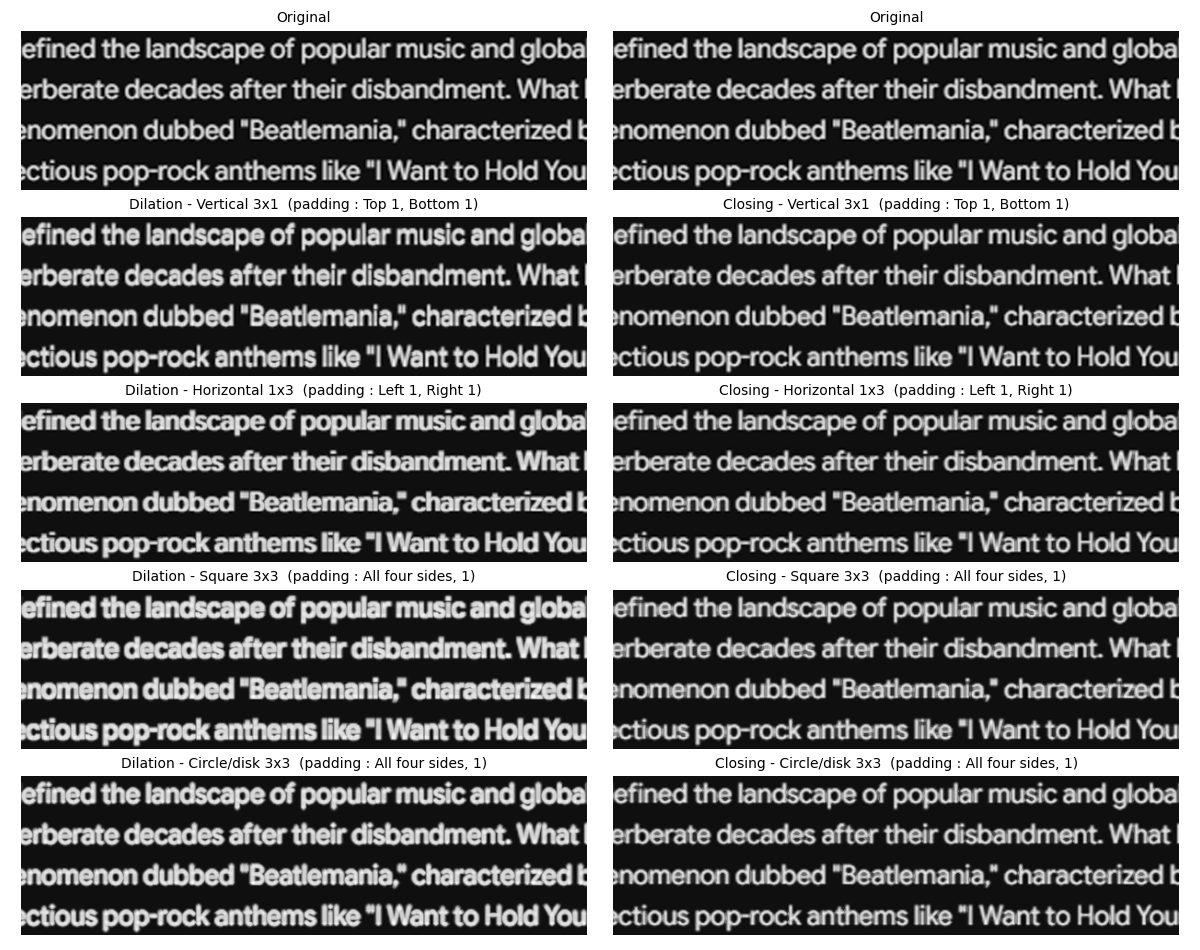


original : bright pixels (> 128) 20754 | mean 56.48
Structuring element Dilation pixels     Dilation mean     Closing pixels      Closing mean      
------------------------------------------------------------------------------------------------
Vertical 3x1        27414 (+32.1%)      69.40 (+12.93)    21260 (+2.4%)       58.00 (+1.53)     
Horizontal 1x3      28512 (+37.4%)      70.71 (+14.23)    21873 (+5.4%)       58.84 (+2.37)     
Square 3x3          35290 (+70.0%)      83.66 (+27.18)    22502 (+8.4%)       60.39 (+3.91)     
Circle/disk 3x3     31834 (+53.4%)      77.43 (+20.95)    21859 (+5.3%)       59.43 (+2.95)     


In [ ]:
def closing(im, se):   # dilation -> erosion with the same structuring element
    return cv2.erode(cv2.dilate(im, se), se)


# small holes inside letters (e, a, o) close up, and narrow gaps are bridged along the element direction
morph_demo(closing, 'Closing', ref=(cv2.dilate, 'Dilation'))   # dilation on the left : closing is less destructive

#05_1. Opening for noise removal

The few specks that do survive are the ones that happened to land next to each other: a pair or
triple of touching pixels is no longer smaller than the element, so opening correctly keeps it.
That is a property of the filter, not a failure of it.

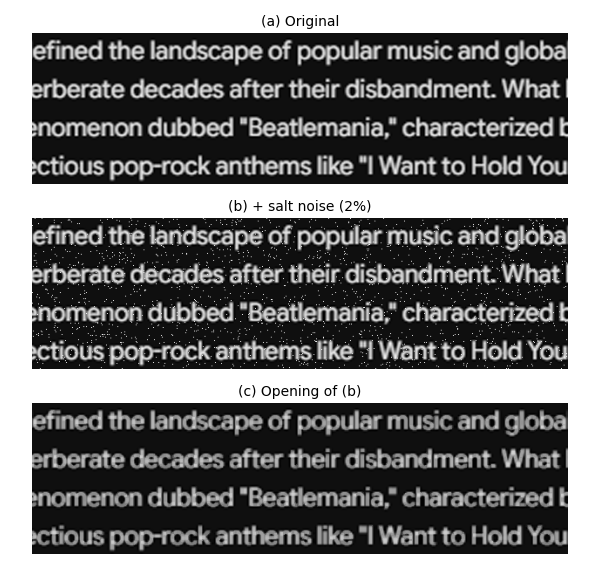


salt specks injected   : 1636
specks still bright    : 67  ->  95.9% removed
text strokes preserved : 100.3% of the noise-free opening
                        bright pixels     mean      
----------------------------------------------------
original                20754             56.48     
+ salt noise            22390             60.00     
opening(noisy)          19120             50.42     


In [ ]:
rng  = np.random.default_rng(0)
salt = text.copy()
spec = (rng.random(text.shape) < 0.02) & (text <= 128)   # isolated bright specks on the background only
salt[spec] = 255

se_sq   = np.ones((3, 3), np.uint8)
cleaned = opening(salt, se_sq)
fg = text > 128

show([text, salt, cleaned], ['(a) Original', '(b) + salt noise (2%)', '(c) Opening of (b)'])

surv = np.count_nonzero(cleaned[spec] > 128)
kept = np.count_nonzero(cleaned[fg] > 128) / np.count_nonzero(opening(text, se_sq)[fg] > 128)
print(f'\nsalt specks injected   : {spec.sum()}')
print(f'specks still bright    : {surv}  ->  {100 - 100 * surv / spec.sum():.1f}% removed')
print(f'text strokes preserved : {100 * kept:.1f}% of the noise-free opening')
print(f'{"":<24}{"bright pixels":<18}{"mean":<10}')
print('-' * 52)
for nm, im in [('original', text), ('+ salt noise', salt), ('opening(noisy)', cleaned)]:
    print(f'{nm:<24}{np.count_nonzero(im > 128):<18}{im.mean():<10.2f}')

#05_2. Closing for gap filling

The dual experiment. Pepper noise punches black holes **into the strokes**, so the letters are
broken up from the inside. Each hole is a single pixel, again smaller than the structuring element,
so by 04_2 closing must fill them while leaving the outline of the letters where it was.

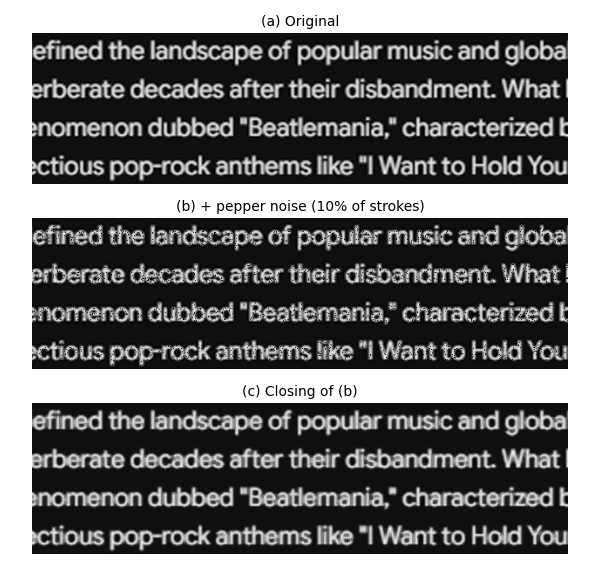


holes punched into strokes : 2054
holes filled back          : 1726  ->  84.0% restored
                        bright pixels     mean      
----------------------------------------------------
original                20754             56.48     
+ pepper noise          18700             52.91     
closing(noisy)          22040             59.94     


In [ ]:
rng  = np.random.default_rng(1)
pep  = text.copy()
hole = (rng.random(text.shape) < 0.10) & fg   # black holes punched into the strokes only
pep[hole] = 0

repaired = closing(pep, se_sq)

show([text, pep, repaired], ['(a) Original', '(b) + pepper noise (10% of strokes)', '(c) Closing of (b)'])

filled = np.count_nonzero(repaired[hole] > 128)
print(f'\nholes punched into strokes : {hole.sum()}')
print(f'holes filled back          : {filled}  ->  {100 * filled / hole.sum():.1f}% restored')
print(f'{"":<24}{"bright pixels":<18}{"mean":<10}')
print('-' * 52)
for nm, im in [('original', text), ('+ pepper noise', pep), ('closing(noisy)', repaired)]:
    print(f'{nm:<24}{np.count_nonzero(im > 128):<18}{im.mean():<10.2f}')

#06. Comparison of the four operations

Dilation and erosion move the amount of ink in opposite directions and change the letter weight a
lot (+70.0% and -68.9%). Opening and closing are the two ways of pairing them, and both land back
near the original weight (-8.4% and +8.4%) - that is the point of a compound operation: it filters
by *size* without rescaling the object.

The two are not inverses of each other, though. Both are
idempotent (applying them twice changes nothing further), but opening discards what is thinner than
the element while closing fills what is narrower than it, so the difference between the opening and
the closing of the same image isolates exactly the detail whose size is comparable to the
structuring element.

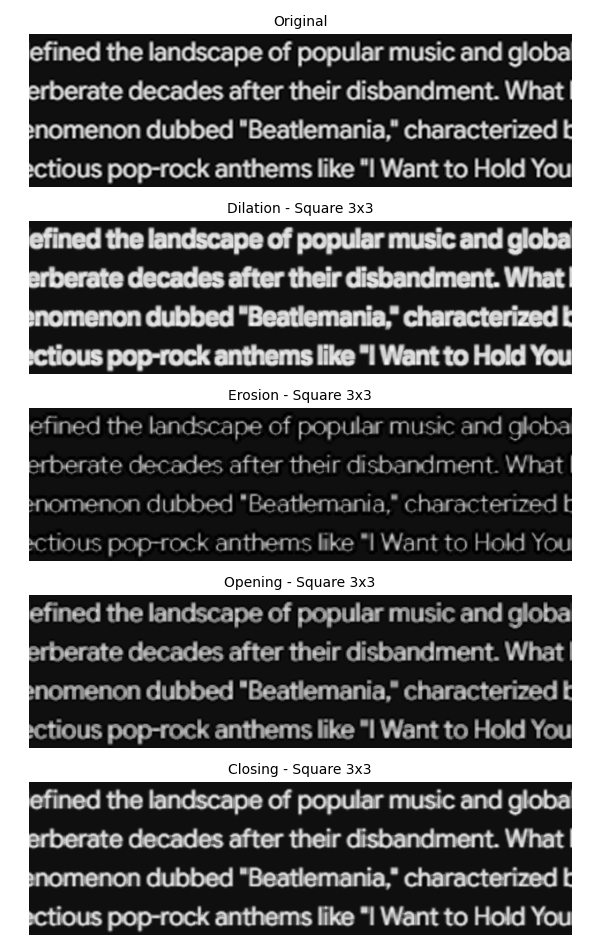

Operation     bright pixels         mean                vs original   
----------------------------------------------------------------------
Original      20754                 56.48               -             
Dilation      35290 (+70.0%)        83.66 (+27.18)      brighter      
Erosion       6454 (-68.9%)         30.28 (-26.19)      darker        
Opening       19001 (-8.4%)         50.29 (-6.19)       darker        
Closing       22502 (+8.4%)         60.39 (+3.91)       brighter      


In [ ]:
res = [('Dilation', cv2.dilate(text, se_sq)), ('Erosion', cv2.erode(text, se_sq)),
       ('Opening', opening(text, se_sq)),     ('Closing', closing(text, se_sq))]

show([text] + [r for _, r in res], ['Original'] + [f'{n} - Square 3x3' for n, _ in res])

print(f'{"Operation":<14}{"bright pixels":<22}{"mean":<20}{"vs original":<14}')
print('-' * 70)
print(f'{"Original":<14}{n0:<22}{m0:<20.2f}{"-":<14}')
for n, r in res:
    c = np.count_nonzero(r > 128)
    rel = 'brighter' if r.mean() > m0 else 'darker'
    print(f'{n:<14}{f"{c} ({100 * c / n0 - 100:+.1f}%)":<22}{f"{r.mean():.2f} ({r.mean() - m0:+.2f})":<20}{rel:<14}')